Explained variance by each principal component: [0.45125272 0.44098465]

Feature impact on each principal component:
          Age  Annual Income (k$)  Spending Score (1-100)
PC1 -0.188974            0.588641                0.785997
PC2  0.130965            0.808376               -0.573914

Average values for each feature within each cluster:
               Age  Annual Income (k$)  Spending Score (1-100)
cluster                                                       
0        44.106557           61.606557               34.532787
1        32.692308           86.538462               82.128205
2        28.564103           31.307692               67.282051
Labeled data saved as 'labeled_mall_customers.csv'


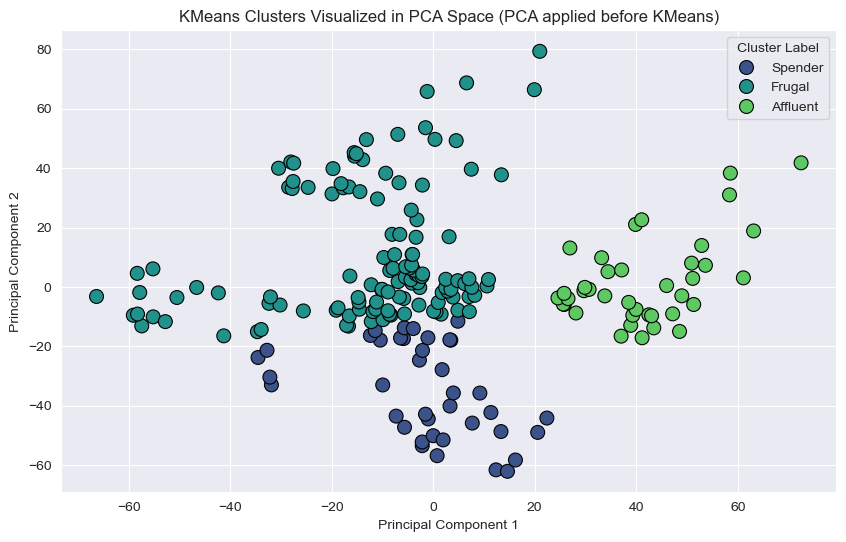

Random Forest Model Accuracy: 0.97
Predicted cluster label for new data: Spender


In [7]:
# Import necessary libraries
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import pandas as pd

# Load and preprocess data
df = pd.read_csv('Mall_Customers.csv')
data = df.drop(['CustomerID', 'Genre'], axis=1)  # Drop unnecessary columns

# Step 1: Apply PCA to reduce to 2 principal components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(data)

# Step 2: Apply KMeans clustering on the PCA-reduced data
kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster'] = kmeans.fit_predict(pca_data)

# Step 3: Interpret the principal components and determine cluster labels
# Feature impact based on PCA components
print("Explained variance by each principal component:", pca.explained_variance_ratio_)
components = pd.DataFrame(pca.components_, columns=data.columns, index=["PC1", "PC2"])
print("\nFeature impact on each principal component:")
print(components)

# Check average values for each feature within each cluster to help assign labels
cluster_means = df.groupby('cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean()
print("\nAverage values for each feature within each cluster:")
print(cluster_means)

# Assign labels based on the cluster characteristics
# You may adjust these labels based on the characteristics found
cluster_labels = {
    0: "Frugal",  # High income and low spending
    1: "Affluent",    # High Income High Spending Affluent
    2: "Spender"    # Lower income, high spending
}
df['cluster_label'] = df['cluster'].map(cluster_labels)

# Save the labeled data to a CSV file
df.to_csv('labeled_mall_customers.csv', index=False)
print("Labeled data saved as 'labeled_mall_customers.csv'")

# Step 4: Visualize clusters in PCA space
pca_df = pd.DataFrame(data=pca_data, columns=["PC1", "PC2"])
pca_df['cluster_label'] = df['cluster_label']

plt.figure(figsize=(10, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="cluster_label", palette="viridis", s=100, edgecolor="k")
plt.title("KMeans Clusters Visualized in PCA Space (PCA applied before KMeans)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster Label")
plt.grid(True)
plt.show()

# Step 5: Train a Random Forest Classifier to predict cluster labels

# Prepare data for the Random Forest classifier
X = data  # Original features
y = df['cluster']  # Numerical cluster labels for model training

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Predict on the test set
y_pred = rf_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Model Accuracy: {accuracy:.2f}")

# Example usage: Predict the cluster for a new data point
new_data = pd.DataFrame([[20, 15, 40]], columns=['Age', 'Annual Income (k$)', 'Spending Score (1-100)'])  # Ensure it matches the feature names in X
predicted_cluster = rf_model.predict(new_data)
predicted_label = cluster_labels[predicted_cluster[0]]
print(f"Predicted cluster label for new data: {predicted_label}")

